In [ ]:
import tensorflow as tf
import numpy as np
import json
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [ ]:
file_path = "/content/1776311302-P3-Car Market Trends Analysis with Car Dekho Data.csv"
df = pd.read_csv(file_path)

In [ ]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 301
Number of Columns: 9


In [ ]:
df.info()
df.describe()
print("Missing Values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB
Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


In [ ]:

duplicates = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicates)

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:")
print(df.shape)

Number of Duplicate Rows: 2
Dataset Shape After Removing Duplicates:
(299, 9)


In [ ]:
for column in df.columns:
    print("\nColumn:", column)
    print("Unique Values:", df[column].nunique())


Column: Car_Name
Unique Values: 98

Column: Year
Unique Values: 16

Column: Selling_Price
Unique Values: 156

Column: Present_Price
Unique Values: 147

Column: Kms_Driven
Unique Values: 206

Column: Fuel_Type
Unique Values: 3

Column: Seller_Type
Unique Values: 2

Column: Transmission
Unique Values: 2

Column: Owner
Unique Values: 3


In [ ]:
CURRENT_YEAR = 2026

df["Car_Age"] = CURRENT_YEAR - df["Year"]

df.head()

/tmp/ipykernel_1520/3840457378.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Car_Age"] = CURRENT_YEAR - df["Year"]


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


In [ ]:
print(df.dtypes)

Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type         object
Seller_Type       object
Transmission      object
Owner              int64
Car_Age            int64
dtype: object


In [ ]:
total_cars = len(df)

print("Total Number of Cars:", total_cars)

Total Number of Cars: 299


In [ ]:
average_price = df["Selling_Price"].mean()

print("Average Selling Price:", round(average_price, 2), "Lakhs")

Average Selling Price: 4.59 Lakhs


In [ ]:
highest_price = df["Selling_Price"].max()

print("Highest Selling Price:", highest_price, "Lakhs")
lowest_price = df["Selling_Price"].min()

print("Lowest Selling Price:", lowest_price, "Lakhs")

Highest Selling Price: 35.0 Lakhs
Lowest Selling Price: 0.1 Lakhs


In [ ]:
fuel_count = df["Fuel_Type"].value_counts()

print(fuel_count)

Fuel_Type
Petrol    239
Diesel     58
CNG         2
Name: count, dtype: int64


In [ ]:
fuel_avg_price = (
    df.groupby("Fuel_Type")["Selling_Price"]
    .mean()
    .sort_values(ascending=False)
)

print(fuel_avg_price)

Fuel_Type
Diesel    10.102759
Petrol     3.264184
CNG        3.100000
Name: Selling_Price, dtype: float64


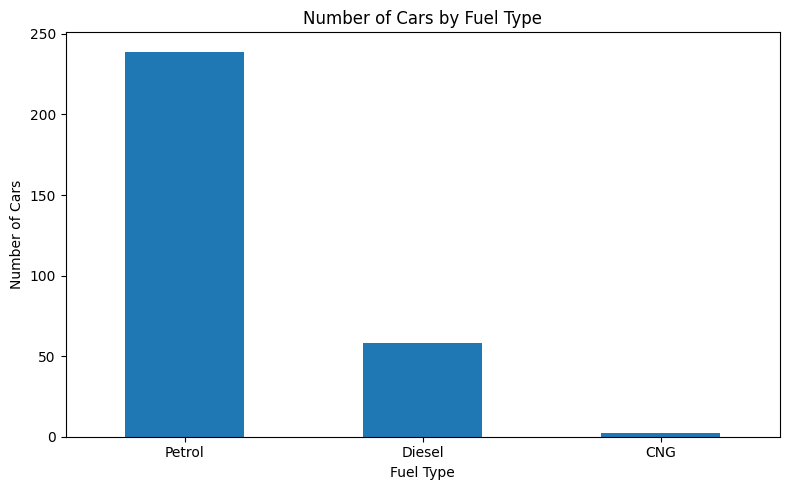

In [ ]:
plt.figure(figsize=(8, 5))

df["Fuel_Type"].value_counts().plot(
    kind="bar"
)

plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

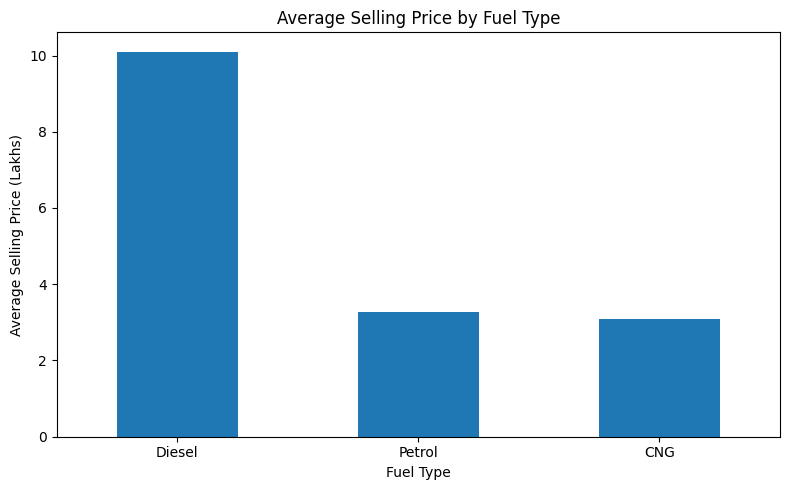

In [ ]:
plt.figure(figsize=(8, 5))

fuel_avg_price.plot(
    kind="bar"
)

plt.title("Average Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Selling Price (Lakhs)")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [ ]:
transmission_count = df["Transmission"].value_counts()

print(transmission_count)

Transmission
Manual       260
Automatic     39
Name: count, dtype: int64


In [ ]:
transmission_avg_price = (
    df.groupby("Transmission")["Selling_Price"]
    .mean()
    .sort_values(ascending=False)
)

print(transmission_avg_price)

Transmission
Automatic    9.071795
Manual       3.917308
Name: Selling_Price, dtype: float64


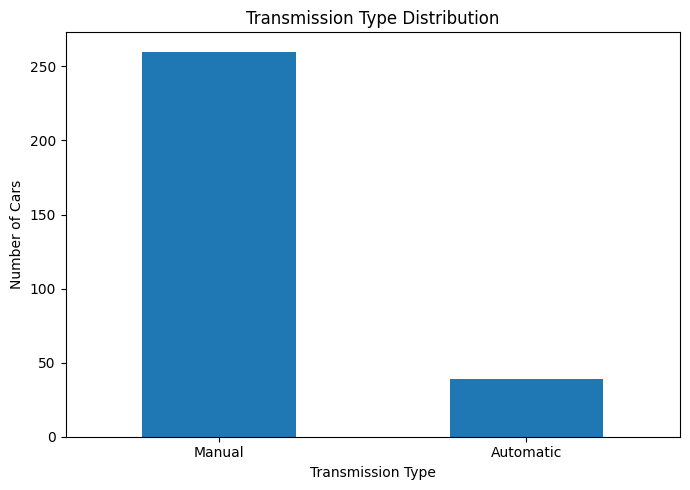

In [ ]:
plt.figure(figsize=(7, 5))

df["Transmission"].value_counts().plot(
    kind="bar"
)

plt.title("Transmission Type Distribution")
plt.xlabel("Transmission Type")
plt.ylabel("Number of Cars")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

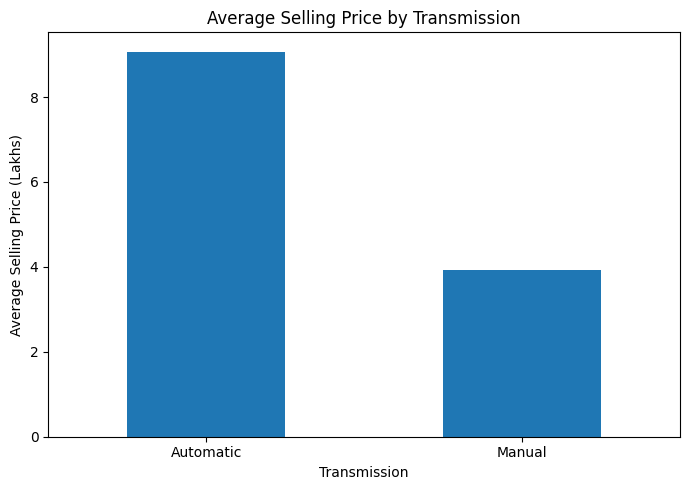

In [ ]:
plt.figure(figsize=(7, 5))

transmission_avg_price.plot(
    kind="bar"
)

plt.title("Average Selling Price by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Average Selling Price (Lakhs)")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [ ]:
seller_count = df["Seller_Type"].value_counts()

print(seller_count)

Seller_Type
Dealer        193
Individual    106
Name: count, dtype: int64


In [ ]:
seller_avg_price = (
    df.groupby("Seller_Type")["Selling_Price"]
    .mean()
    .sort_values(ascending=False)
)

print(seller_avg_price)

Seller_Type
Dealer        6.632021
Individual    0.870943
Name: Selling_Price, dtype: float64


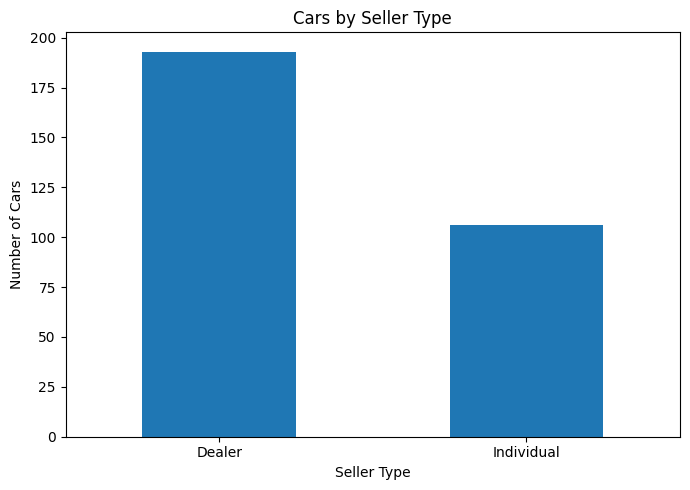

In [ ]:
plt.figure(figsize=(7, 5))

df["Seller_Type"].value_counts().plot(
    kind="bar"
)

plt.title("Cars by Seller Type")
plt.xlabel("Seller Type")
plt.ylabel("Number of Cars")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [ ]:
average_age = df["Car_Age"].mean()

print("Average Car Age:", round(average_age, 2), "Years")

Average Car Age: 12.38 Years


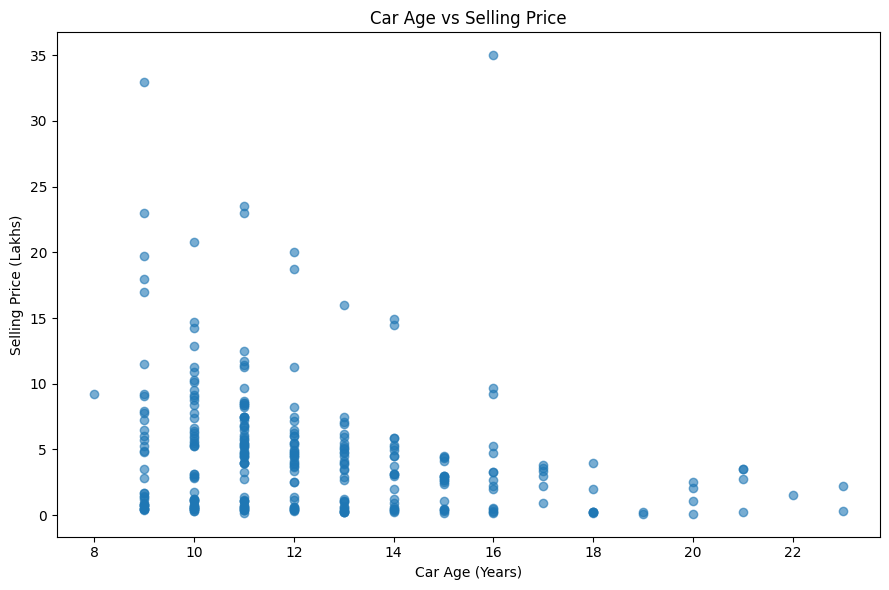

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Car_Age"],
    df["Selling_Price"],
    alpha=0.6
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (Lakhs)")

plt.tight_layout()
plt.show()

In [ ]:
age_price = (
    df.groupby("Car_Age")["Selling_Price"]
    .mean()
)

print(age_price)

Car_Age
8     9.250000
9     6.209143
10    5.161429
11    5.642500
12    4.762105
13    3.540909
14    3.841304
15    2.375263
16    5.262667
17    2.816667
18    1.002857
19    0.160000
20    1.437500
21    2.487500
22    1.500000
23    1.300000
Name: Selling_Price, dtype: float64


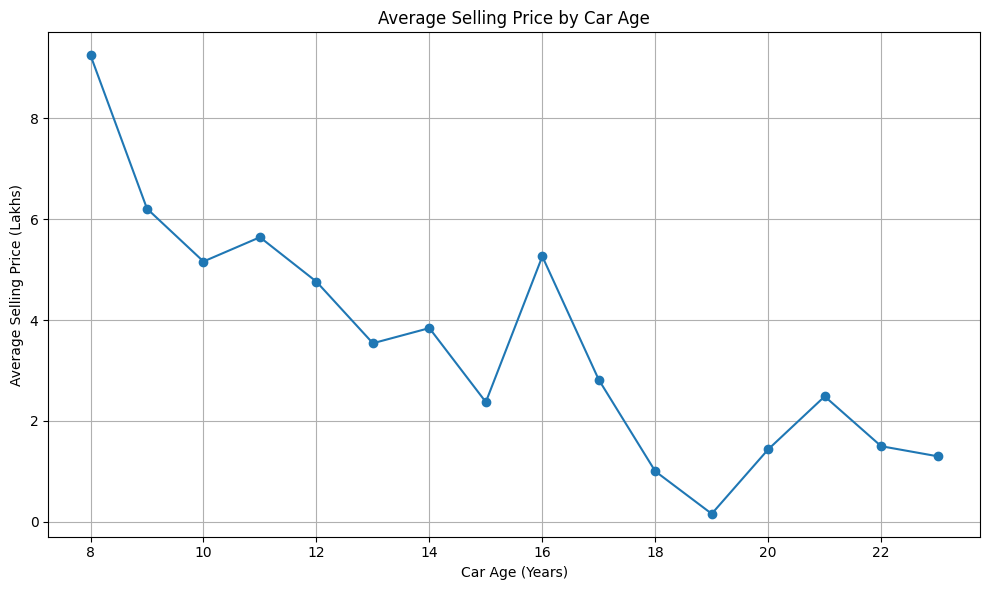

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    age_price.index,
    age_price.values,
    marker="o"
)

plt.title("Average Selling Price by Car Age")
plt.xlabel("Car Age (Years)")
plt.ylabel("Average Selling Price (Lakhs)")

plt.grid()
plt.tight_layout()

plt.show()

In [ ]:
print("Average Kilometers Driven:",
      round(df["Kms_Driven"].mean(), 2))

print("Maximum Kilometers Driven:",
      df["Kms_Driven"].max())

print("Minimum Kilometers Driven:",
      df["Kms_Driven"].min())

Average Kilometers Driven: 36916.75
Maximum Kilometers Driven: 500000
Minimum Kilometers Driven: 500


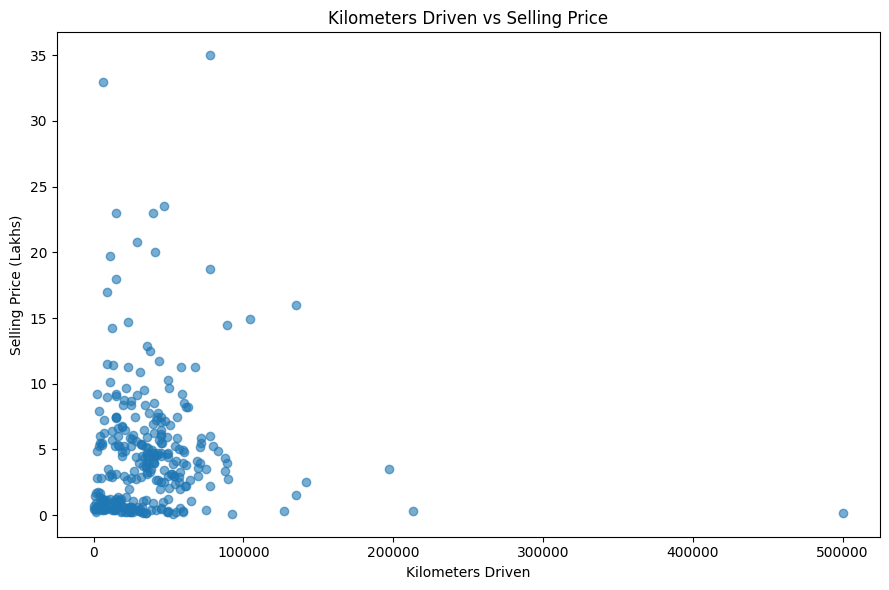

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Kms_Driven"],
    df["Selling_Price"],
    alpha=0.6
)

plt.title("Kilometers Driven vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price (Lakhs)")

plt.tight_layout()
plt.show()

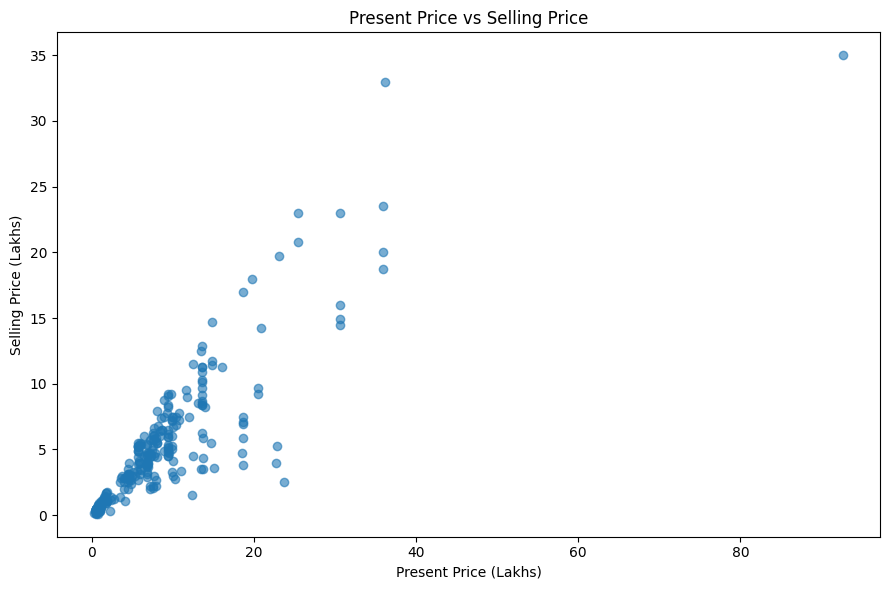

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Present_Price"],
    df["Selling_Price"],
    alpha=0.6
)

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price (Lakhs)")
plt.ylabel("Selling Price (Lakhs)")

plt.tight_layout()
plt.show()

In [ ]:
df["Price_Difference"] = (
    df["Present_Price"] -
    df["Selling_Price"]
)

df[
    [
        "Car_Name",
        "Present_Price",
        "Selling_Price",
        "Price_Difference"
    ]
].head()

/tmp/ipykernel_1520/2412886876.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Price_Difference"] = (


,Car_Name,Present_Price,Selling_Price,Price_Difference
0,ritz,5.59,3.35,2.24
1,sx4,9.54,4.75,4.79
2,ciaz,9.85,7.25,2.60
3,wagon r,4.15,2.85,1.30
4,swift,6.87,4.60,2.27


In [ ]:
top_price_difference = (
    df[
        [
            "Car_Name",
            "Present_Price",
            "Selling_Price",
            "Price_Difference"
        ]
    ]
    .sort_values(
        by="Price_Difference",
        ascending=False
    )
    .head(10)
)

top_price_difference

,Car_Name,Present_Price,Selling_Price,Price_Difference
86,land cruiser,92.60,35.00,57.60
85,camry,23.73,2.50,21.23
94,corolla altis,22.78,4.00,18.78
78,corolla altis,22.83,5.25,17.58
62,fortuner,35.96,18.75,17.21
79,fortuner,30.61,14.50,16.11
59,fortuner,35.96,19.99,15.97
50,fortuner,30.61,14.90,15.71
90,corolla altis,18.61,3.80,14.81
53,fortuner,30.61,16.00,14.61


In [ ]:
popular_cars = (
    df["Car_Name"]
    .value_counts()
    .head(10)
)

print(popular_cars)

Car_Name
city                         26
corolla altis                16
verna                        14
brio                         10
fortuner                     10
ciaz                          9
i20                           9
innova                        9
grand i10                     8
Royal Enfield Classic 350     7
Name: count, dtype: int64


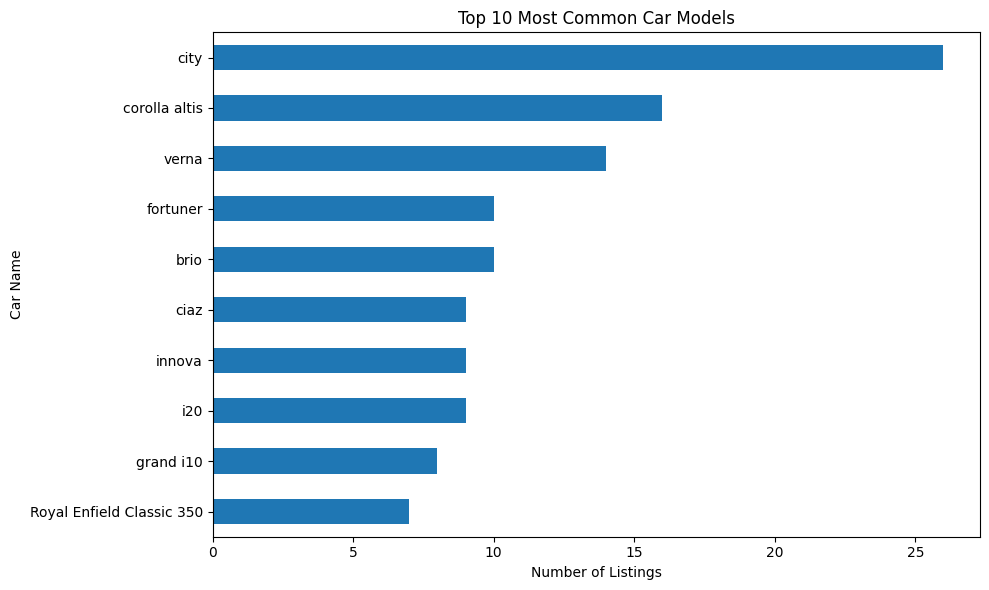

In [ ]:
plt.figure(figsize=(10, 6))

popular_cars.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Most Common Car Models")
plt.xlabel("Number of Listings")
plt.ylabel("Car Name")

plt.tight_layout()
plt.show()

In [ ]:
most_expensive_cars = (
    df[
        [
            "Car_Name",
            "Year",
            "Selling_Price"
        ]
    ]
    .sort_values(
        by="Selling_Price",
        ascending=False
    )
    .head(10)
)

most_expensive_cars

,Car_Name,Year,Selling_Price
86,land cruiser,2010,35.00
64,fortuner,2017,33.00
63,fortuner,2015,23.50
82,innova,2017,23.00
51,fortuner,2015,23.00
96,innova,2016,20.75
59,fortuner,2014,19.99
66,innova,2017,19.75
62,fortuner,2014,18.75
52,innova,2017,18.00


In [ ]:
owner_count = (
    df["Owner"]
    .value_counts()
    .sort_index()
)

print(owner_count)

Owner
0    288
1     10
3      1
Name: count, dtype: int64


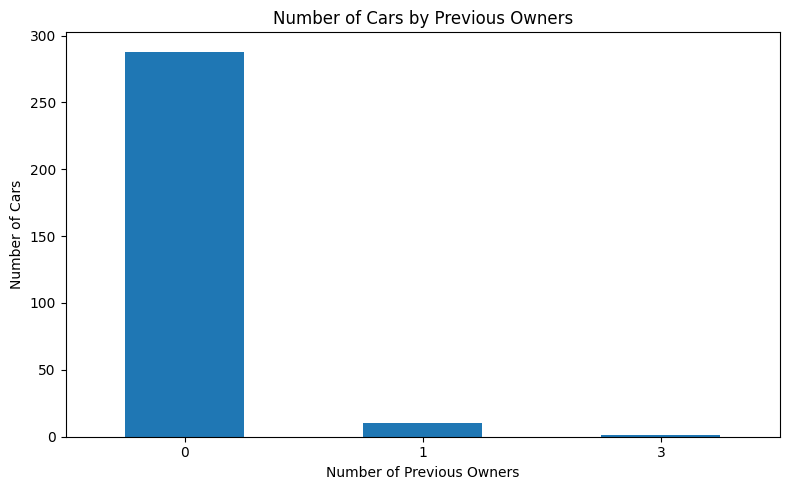

In [ ]:
plt.figure(figsize=(8, 5))

owner_count.plot(
    kind="bar"
)

plt.title("Number of Cars by Previous Owners")
plt.xlabel("Number of Previous Owners")
plt.ylabel("Number of Cars")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [ ]:
numeric_df = df.select_dtypes(
    include=np.number
)

numeric_df.head()


,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Price_Difference
0,2014,3.35,5.59,27000,0,12,2.24
1,2013,4.75,9.54,43000,0,13,4.79
2,2017,7.25,9.85,6900,0,9,2.60
3,2011,2.85,4.15,5200,0,15,1.30
4,2014,4.60,6.87,42450,0,12,2.27


In [ ]:
correlation_matrix = numeric_df.corr()

correlation_matrix

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Price_Difference
Year,1.000000,0.234369,-0.053563,-0.525714,-0.181639,-1.000000,-0.336349
Selling_Price,0.234369,1.000000,0.876378,0.028566,-0.087880,-0.234369,0.521860
Present_Price,-0.053563,0.876378,1.000000,0.205253,0.009947,0.053563,0.868186
Kms_Driven,-0.525714,0.028566,0.205253,1.000000,0.089367,0.525714,0.334104
Owner,-0.181639,-0.087880,0.009947,0.089367,1.000000,0.181639,0.108164
Car_Age,-1.000000,-0.234369,0.053563,0.525714,0.181639,1.000000,0.336349
Price_Difference,-0.336349,0.521860,0.868186,0.334104,0.108164,0.336349,1.000000


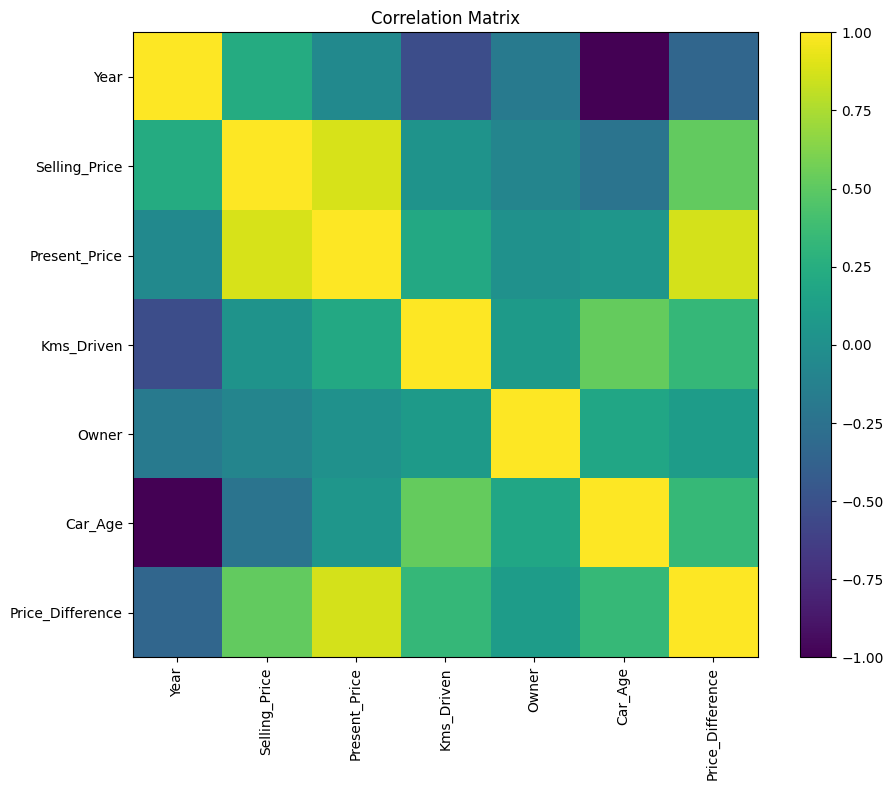

In [ ]:
plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [ ]:
fuel_transmission = pd.crosstab(
    df["Fuel_Type"],
    df["Transmission"]
)

fuel_transmission



Transmission,Automatic,Manual
Fuel_Type,,
CNG,0,2
Diesel,11,47
Petrol,28,211


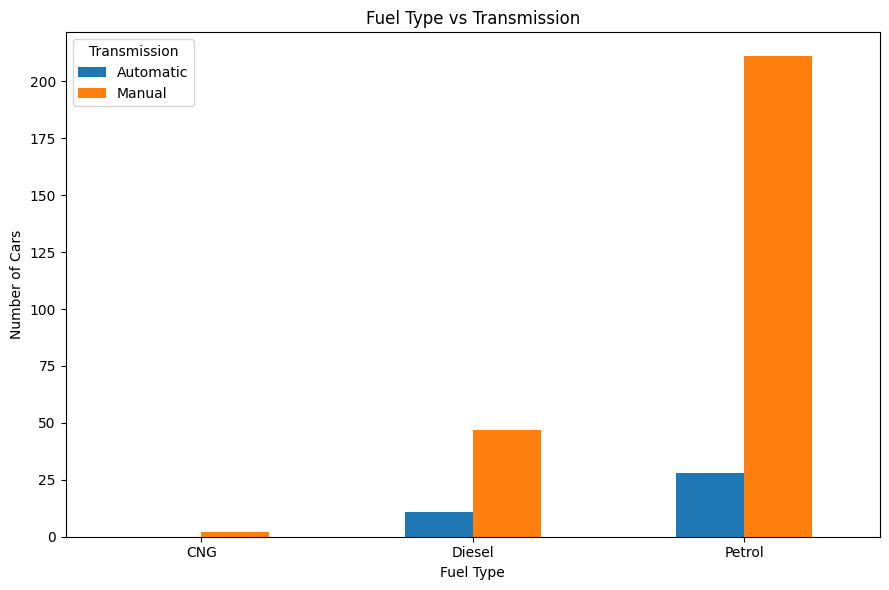

In [ ]:
fuel_transmission.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Fuel Type vs Transmission")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

Year
2003    1.300000
2004    1.500000
2005    2.487500
2006    1.437500
2007    0.160000
2008    1.002857
2009    2.816667
2010    5.262667
2011    2.375263
2012    3.841304
2013    3.540909
2014    4.762105
2015    5.642500
2016    5.161429
2017    6.209143
2018    9.250000
Name: Selling_Price, dtype: float64


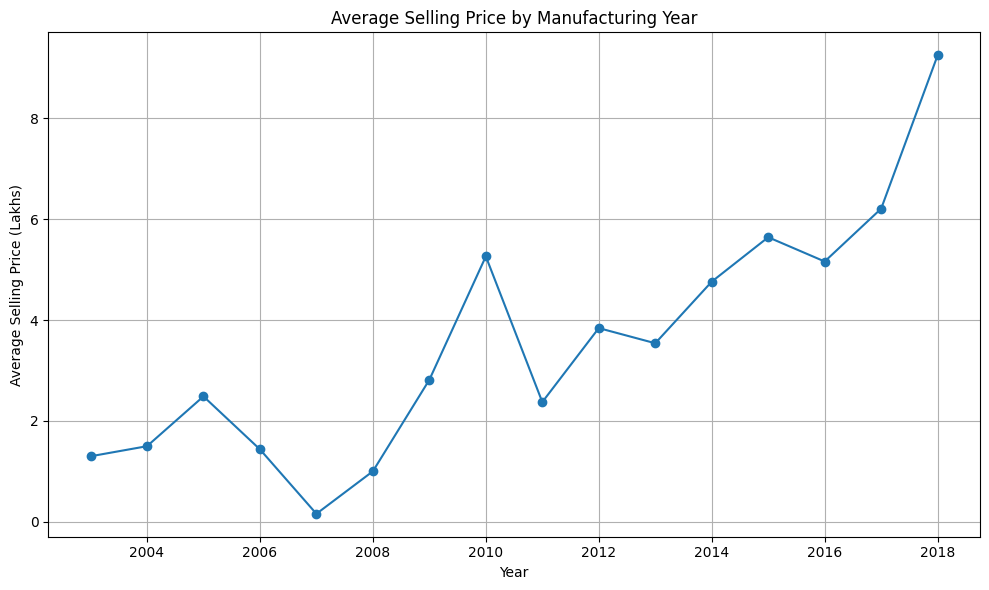

In [ ]:
year_price = (
    df.groupby("Year")["Selling_Price"]
    .mean()
    .sort_index()
)

print(year_price)
plt.figure(figsize=(10, 6))

plt.plot(
    year_price.index,
    year_price.values,
    marker="o"
)

plt.title("Average Selling Price by Manufacturing Year")
plt.xlabel("Year")
plt.ylabel("Average Selling Price (Lakhs)")

plt.grid()
plt.tight_layout()

plt.show()

In [ ]:
print("=" * 50)
print("CAR MARKET TRENDS ANALYSIS - KEY INSIGHTS")
print("=" * 50)

print("\n1. Total Cars:")
print(len(df))

print("\n2. Average Selling Price:")
print(round(df["Selling_Price"].mean(), 2), "Lakhs")

print("\n3. Highest Selling Price:")
print(df["Selling_Price"].max(), "Lakhs")

print("\n4. Lowest Selling Price:")
print(df["Selling_Price"].min(), "Lakhs")

print("\n5. Most Common Fuel Type:")
print(df["Fuel_Type"].mode()[0])

print("\n6. Most Common Transmission:")
print(df["Transmission"].mode()[0])

print("\n7. Most Common Seller Type:")
print(df["Seller_Type"].mode()[0])

print("\n8. Most Popular Car Model:")
print(df["Car_Name"].mode()[0])

print("\n9. Average Car Age:")
print(round(df["Car_Age"].mean(), 2), "Years")

print("\n10. Average Kilometers Driven:")
print(round(df["Kms_Driven"].mean(), 2))

print("\n" + "=" * 50)
print("ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 50)

CAR MARKET TRENDS ANALYSIS - KEY INSIGHTS

1. Total Cars:
299

2. Average Selling Price:
4.59 Lakhs

3. Highest Selling Price:
35.0 Lakhs

4. Lowest Selling Price:
0.1 Lakhs

5. Most Common Fuel Type:
Petrol

6. Most Common Transmission:
Manual

7. Most Common Seller Type:
Dealer

8. Most Popular Car Model:
city

9. Average Car Age:
12.38 Years

10. Average Kilometers Driven:
36916.75

ANALYSIS COMPLETED SUCCESSFULLY


In [ ]:
df.to_csv(
    "Cleaned_CarDekho_Data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
# Calculate Depreciation Amount
df["Depreciation_Amount"] = (
    df["Present_Price"] - df["Selling_Price"]
)

# Calculate Depreciation Percentage
df["Depreciation_Percentage"] = (
    (df["Depreciation_Amount"] / df["Present_Price"]) * 100
)

df[[
    "Car_Name",
    "Present_Price",
    "Selling_Price",
    "Depreciation_Percentage"
]].head()

/tmp/ipykernel_1520/541212253.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Depreciation_Amount"] = (
/tmp/ipykernel_1520/541212253.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Depreciation_Percentage"] = (


,Car_Name,Present_Price,Selling_Price,Depreciation_Percentage
0,ritz,5.59,3.35,40.071556
1,sx4,9.54,4.75,50.209644
2,ciaz,9.85,7.25,26.395939
3,wagon r,4.15,2.85,31.325301
4,swift,6.87,4.60,33.042213


In [ ]:
age_depreciation = (
    df.groupby("Car_Age")
    .agg({
        "Depreciation_Percentage": "mean",
        "Selling_Price": "mean"
    })
)

age_depreciation

,Depreciation_Percentage,Selling_Price
Car_Age,,
8,5.900305,9.250000
9,12.148819,6.209143
10,21.129154,5.161429
11,27.841800,5.642500
12,38.393792,4.762105
13,43.150762,3.540909
14,49.335300,3.841304
15,50.844368,2.375263
16,61.082493,5.262667


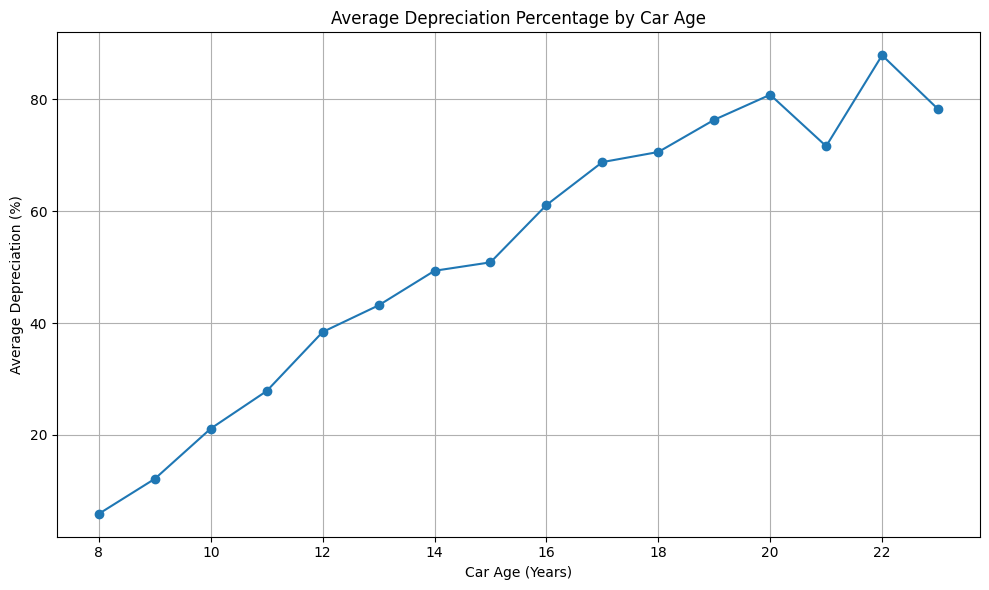

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    age_depreciation.index,
    age_depreciation["Depreciation_Percentage"],
    marker="o"
)

plt.title("Average Depreciation Percentage by Car Age")
plt.xlabel("Car Age (Years)")
plt.ylabel("Average Depreciation (%)")

plt.grid()
plt.tight_layout()

plt.show()

In [ ]:
df["Value_Score"] = (
    df["Selling_Price"] / df["Present_Price"]
)

value_cars = (
    df[[
        "Car_Name",
        "Year",
        "Selling_Price",
        "Present_Price",
        "Kms_Driven",
        "Value_Score"
    ]]
    .sort_values(
        by="Value_Score",
        ascending=False
    )
)

value_cars.head(10)

/tmp/ipykernel_1520/676714624.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Value_Score"] = (


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Value_Score
80,corolla altis,2016,14.73,14.89,23000,0.989255
8,ciaz,2016,8.75,8.89,20273,0.984252
231,verna,2017,9.25,9.40,15001,0.984043
208,i20,2017,7.90,8.10,3435,0.975309
235,verna,2017,9.10,9.40,15141,0.968085
234,grand i10,2015,5.50,5.70,4492,0.964912
250,creta,2016,12.90,13.60,35934,0.948529
126,Bajaj Avenger 220,2017,0.90,0.95,1300,0.947368
155,Honda Activa 4G,2017,0.48,0.51,4300,0.941176
5,vitara brezza,2018,9.25,9.83,2071,0.940997


/tmp/ipykernel_1520/2462649985.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Price_Category"] = (


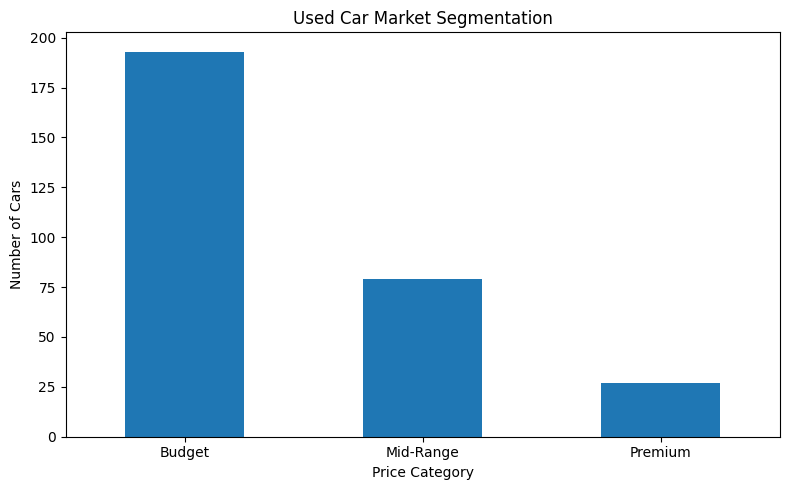

In [ ]:
def price_category(price):

    if price < 5:
        return "Budget"

    elif price < 10:
        return "Mid-Range"

    else:
        return "Premium"


df["Price_Category"] = (
    df["Selling_Price"]
    .apply(price_category)
)

df["Price_Category"].value_counts()
category_count = df["Price_Category"].value_counts()

plt.figure(figsize=(8, 5))

category_count.plot(
    kind="bar"
)

plt.title("Used Car Market Segmentation")
plt.xlabel("Price Category")
plt.ylabel("Number of Cars")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [ ]:
def recommend_cars(
    budget,
    fuel_type=None,
    transmission=None
):

    recommendations = df[
        df["Selling_Price"] <= budget
    ]

    if fuel_type:
        recommendations = recommendations[
            recommendations["Fuel_Type"] == fuel_type
        ]

    if transmission:
        recommendations = recommendations[
            recommendations["Transmission"] == transmission
        ]

    recommendations = recommendations.sort_values(
        by=[
            "Year",
            "Kms_Driven",
            "Selling_Price"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )

    return recommendations.head(10)

    recommend_cars(
    budget=5,
    fuel_type="Petrol",
    transmission="Manual"
)

In [ ]:
print("=" * 60)
print("        CARDEKHO MARKET INTELLIGENCE DASHBOARD")
print("=" * 60)

print(f"""
Total Cars Analyzed: {len(df)}

Average Selling Price: ₹{df["Selling_Price"].mean():.2f} Lakhs

Highest Selling Price: ₹{df["Selling_Price"].max():.2f} Lakhs

Average Car Age: {df["Car_Age"].mean():.1f} Years

Average Kilometers Driven:
{df["Kms_Driven"].mean():,.0f} KM

Most Popular Fuel Type:
{df["Fuel_Type"].mode()[0]}

Most Popular Transmission:
{df["Transmission"].mode()[0]}

Most Popular Car:
{df["Car_Name"].mode()[0]}
""")

print("=" * 60)

        CARDEKHO MARKET INTELLIGENCE DASHBOARD

Total Cars Analyzed: 299

Average Selling Price: ₹4.59 Lakhs

Highest Selling Price: ₹35.00 Lakhs

Average Car Age: 12.4 Years

Average Kilometers Driven:
36,917 KM

Most Popular Fuel Type:
Petrol

Most Popular Transmission:
Manual

Most Popular Car:
city

